# Task 1 - Study and prepare the data

This is where we look at CIFAR-10 and set up the data for the rest of the assignment. Most of the actual code is in `cifar_data.py`, so the other tasks can just import the same split and stats instead of everyone doing their own (which would make the comparisons pretty meaningless).

Run it from the repo root. The first run downloads the dataset (around 163 MB) into `data/` and saves the split to `splits/cifar10_split.json` - the split file is in git, the data isn't. Figures get saved to `figures/task1/` for the report.

In [1]:
import hashlib
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from cifar_data import (load_cifar10, get_split, make_split, make_loaders, make_test_loader,
                        RawImages, prepare_inputs, training_augmentation, set_seed,
                        CLASS_NAMES, INPUT_SIZES, SPLIT_SEED)

FIG_DIR = Path("figures/task1")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0+cpu | device: cpu


## Loading the data

We use the 50k training images for everything during development and keep the 10k test images for the end.

In [2]:
data = load_cifar10()
database, test_database = data["train"], data["test"]
labels = np.asarray(database.targets)
test_labels = np.asarray(test_database.targets)

print("Training array:", database.data.shape, database.data.dtype, "[N, H, W, C]")
print("Test array:    ", test_database.data.shape, test_database.data.dtype)
print("Pixel range:   ", database.data.min(), "to", database.data.max())
print("Classes:       ", CLASS_NAMES)

100%|██████████| 170M/170M [00:06<00:00, 26.9MB/s] 


Training array: (50000, 32, 32, 3) uint8 [N, H, W, C]
Test array:     (10000, 32, 32, 3) uint8
Pixel range:    0 to 255
Classes:        ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## What does an example represent?

Each example is a 32x32 colour image (uint8, so 0-255) with one label out of 10 classes, and the classes don't overlap. For the image ID we just use the index of the image in the original training set(or test set) - that way an ID is the same image for all of us.

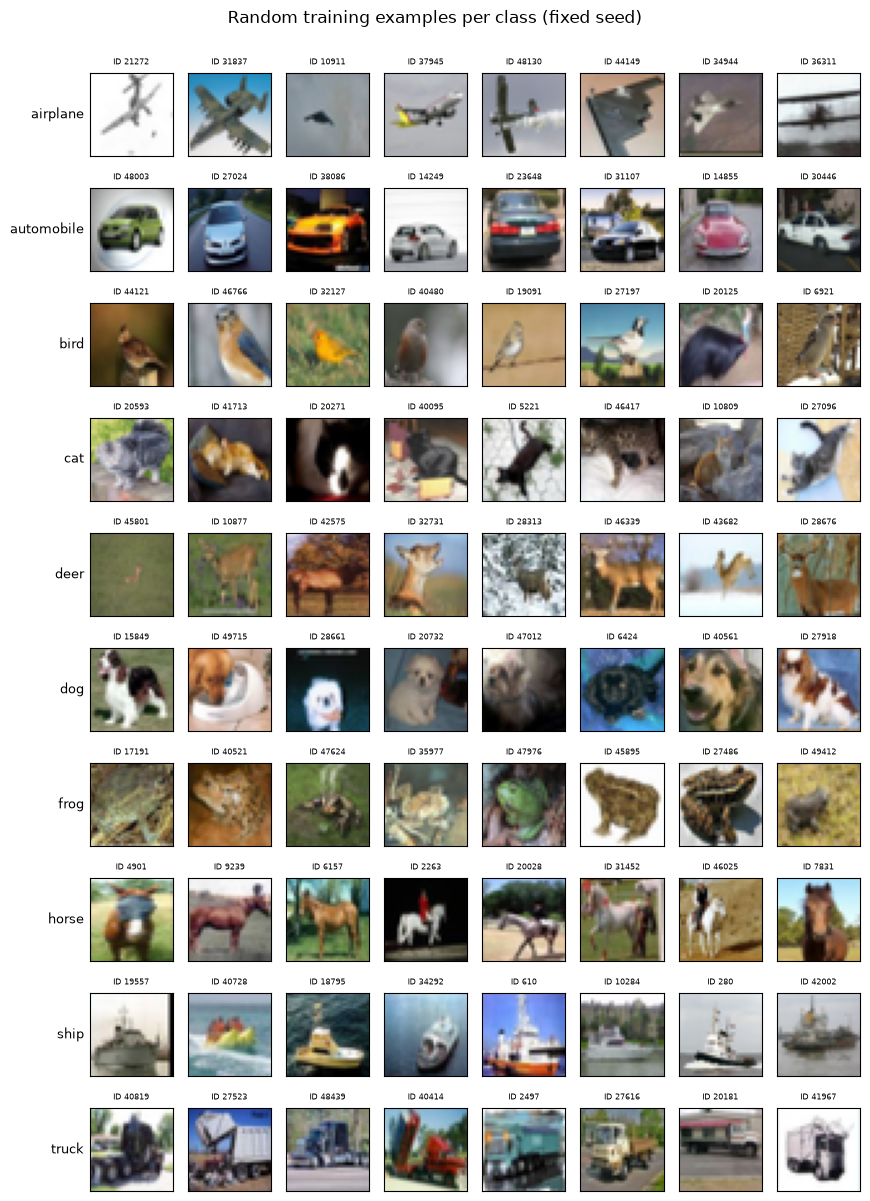

In [3]:
n_per_class = 8
fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.1, 10 * 1.2))
rng = np.random.default_rng(SPLIT_SEED)
for c, name in enumerate(CLASS_NAMES):
    ids = rng.choice(np.flatnonzero(labels == c), n_per_class, replace=False)
    for j, image_id in enumerate(ids):
        ax = axes[c, j]
        ax.imshow(database.data[image_id])
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"ID {image_id}", fontsize=6)
        if j == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Random training examples per class (fixed seed)", y=1.0)
fig.tight_layout()
save(fig, "examples_per_class")
plt.show()

## How are the classes distributed?

,official train,official test
class,,
airplane,5000,1000
automobile,5000,1000
bird,5000,1000
cat,5000,1000
deer,5000,1000
dog,5000,1000
frog,5000,1000
horse,5000,1000
ship,5000,1000


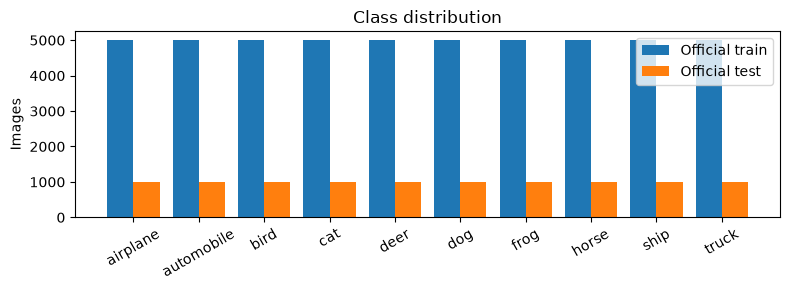

Perfectly balanced: True


In [4]:
distribution = pd.DataFrame({
    "class": CLASS_NAMES,
    "official train": np.bincount(labels, minlength=10),
    "official test": np.bincount(test_labels, minlength=10),
})
display(distribution.set_index("class"))

fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(10)
ax.bar(x - 0.2, distribution["official train"], 0.4, label="Official train")
ax.bar(x + 0.2, distribution["official test"], 0.4, label="Official test")
ax.set_xticks(x, CLASS_NAMES, rotation=30)
ax.set_ylabel("Images")
ax.set_title("Class distribution")
ax.legend()
fig.tight_layout()
save(fig, "class_distribution")
plt.show()

balanced = distribution["official train"].nunique() == 1 and distribution["official test"].nunique() == 1
print("Perfectly balanced:", balanced)

The classes are completely balanced (5000 train and 1000 test images each), so accuracy is a fair metric to use and random guessing would get 10%. We will still look at per class results later though, since some classes will probably get mixed up a lot (for example cat/dog).

## What do the classes look like on average?

Mean image per class, mainly to see if there are any obvious background cues the models could pick up on (sky behind planes, water behind ships etc).

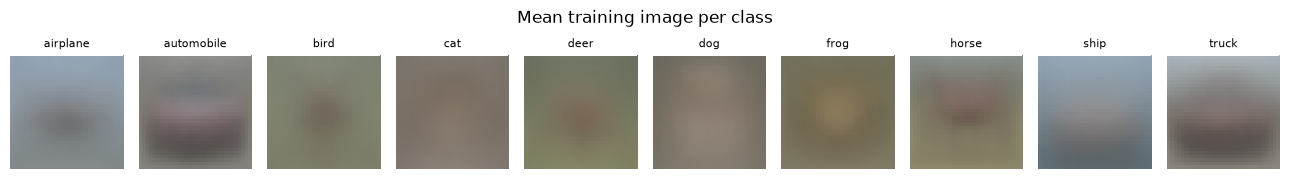

,red,green,blue,brightness
airplane,0.526,0.560,0.589,0.558
automobile,0.471,0.455,0.447,0.458
bird,0.489,0.491,0.424,0.468
cat,0.495,0.456,0.416,0.456
deer,0.472,0.465,0.378,0.438
dog,0.500,0.465,0.417,0.461
frog,0.470,0.438,0.345,0.418
horse,0.502,0.480,0.417,0.466
ship,0.490,0.525,0.555,0.523
truck,0.499,0.485,0.478,0.487


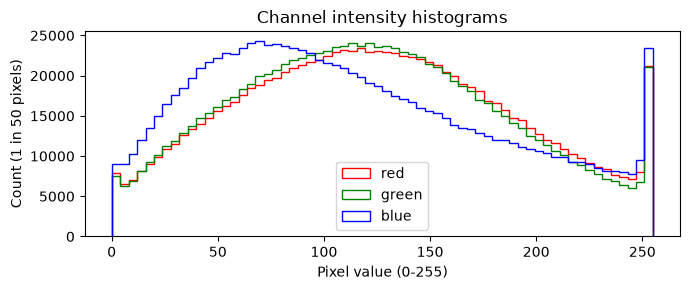

In [5]:
images = database.data.astype(np.float32) / 255
class_means = np.stack([images[labels == c].mean(axis=0) for c in range(10)])

fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for c, ax in enumerate(axes):
    ax.imshow(class_means[c])
    ax.set_title(CLASS_NAMES[c], fontsize=8)
    ax.axis("off")
fig.suptitle("Mean training image per class")
fig.tight_layout()
save(fig, "mean_image_per_class")
plt.show()

colour = pd.DataFrame(class_means.mean(axis=(1, 2)), columns=["red", "green", "blue"],
                      index=CLASS_NAMES).round(3)
colour["brightness"] = colour.mean(axis=1).round(3)
display(colour)

fig, ax = plt.subplots(figsize=(7, 3))
for ch, name in enumerate(["red", "green", "blue"]):
    ax.hist(database.data[..., ch].ravel()[::50], bins=64, histtype="step", color=name, label=name)
ax.set(xlabel="Pixel value (0-255)", ylabel="Count (1 in 50 pixels)", title="Channel intensity histograms")
ax.legend()
fig.tight_layout()
save(fig, "channel_histograms")
plt.show()
del images

## Are there duplicates?

CIFAR-10 is known to have near-duplicates between train and test (Barz & Denzler, 2020). Finding near-duplicates properly would take a lot more work, so here we only check for exact duplicates by hashing the pixel values.

In [6]:
def image_hashes(array):
    return [hashlib.md5(img.tobytes()).hexdigest() for img in array]

train_hashes = image_hashes(database.data)
test_hashes = image_hashes(test_database.data)
train_series = pd.Series(train_hashes)
exact_within_train = int(train_series.duplicated().sum())
exact_train_test = len(set(train_hashes) & set(test_hashes))
print("Exact duplicate images within the training set:", exact_within_train)
print("Test images whose exact pixels also appear in training:", exact_train_test)

Exact duplicate images within the training set: 0
Test images whose exact pixels also appear in training: 0


## How is the data split?

We split the official training set into 45k train and 5k validation. It's stratified so every class gets exactly 500 validation images, and we use the same seed as Part A (2223). Validation is used for all the tuning and checkpoint choices, and the test set only gets used once at the very end on the final models.

The IDs and the normalisation stats are saved to `splits/cifar10_split.json` and pushed to the repo, so we all use exactly the same split even if someone has a different sklearn version.

In [7]:
split = get_split(database)
train_ids, val_ids, stats = split["train_ids"], split["val_ids"], split["stats"]
test_ids = np.arange(len(test_database))

split_table = pd.DataFrame({
    "train": np.bincount(labels[train_ids], minlength=10),
    "validation": np.bincount(labels[val_ids], minlength=10),
    "test": np.bincount(test_labels, minlength=10),
}, index=CLASS_NAMES)
split_table.loc["total"] = split_table.sum()
display(split_table)

assert set(train_ids).isdisjoint(val_ids)
assert len(train_ids) + len(val_ids) == len(database)
assert (split_table.loc[CLASS_NAMES, "validation"] == 500).all()
print("First training IDs:  ", train_ids[:8])
print("First validation IDs:", val_ids[:8])

,train,validation,test
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000
truck,4500,500,1000


First training IDs:   [0 1 2 3 4 5 6 7]
First validation IDs: [14 15 16 39 45 59 64 72]


## Normalisation

Per channel mean and std, calculated on the 45k training images only - if we used val or test images as well, information from them would leak into the preprocessing. After normalising, the training data should have a mean around 0 and std around 1, which the cell below checks.

In [8]:
display(pd.DataFrame(stats, index=["red", "green", "blue"]).round(4))

check_loader = torch.utils.data.DataLoader(RawImages(database, train_ids[:5000]), batch_size=1000)
normalised = torch.cat([prepare_inputs(raw, stats, 32) for raw, _, _ in check_loader])
print("Normalised training sample, per-channel mean:", normalised.mean(dim=(0, 2, 3)).numpy().round(3))
print("Normalised training sample, per-channel std: ", normalised.std(dim=(0, 2, 3)).numpy().round(3))

val_loader_check = torch.utils.data.DataLoader(RawImages(database, val_ids), batch_size=1000)
val_norm = torch.cat([prepare_inputs(raw, stats, 32) for raw, _, _ in val_loader_check])
print("Normalised validation set, per-channel mean: ", val_norm.mean(dim=(0, 2, 3)).numpy().round(3))

,mean,std
red,0.4913,0.2470
green,0.4822,0.2434
blue,0.4464,0.2615


Normalised training sample, per-channel mean: [-0.001 -0.006 -0.012]
Normalised training sample, per-channel std:  [1.006 1.007 1.006]
Normalised validation set, per-channel mean:  [ 0.003 -0.001  0.005]


## Which preprocessing do the two models need?

Both of the CIFAR-10 versions in A9 are made for 32x32 images, so we don't resize anything. Upscaling to 224x224 like the original ImageNet models wouldn't add any information and would be around 49x more compute per image. So both models get the same preprocessing: convert to a tensor in [0,1] and then normalise.

Like in Part A, the normalising is done in `prepare_inputs` in the model call instead of in the dataset. This means the loaders give raw pixels, which makes the corruptions in Task 4 and the adversarial attack in Task 5 easier (epsilon can just be in pixel units, e.g. 4/255).

In [9]:
raw_batch, target_batch, id_batch = next(iter(torch.utils.data.DataLoader(RawImages(database, val_ids), batch_size=16)))
print("Raw batch:", tuple(raw_batch.shape), "range", (raw_batch.min().item(), raw_batch.max().item()))
for model_name in ["alexnet", "resnet18"]:
    size = INPUT_SIZES[model_name]
    prepared = prepare_inputs(raw_batch, stats, size)
    print(f"{model_name:9s} input size {size}: prepared batch {tuple(prepared.shape)}")

Raw batch: (16, 3, 32, 32) range (0.0, 1.0)
alexnet   input size 32: prepared batch (16, 3, 32, 32)
resnet18  input size 32: prepared batch (16, 3, 32, 32)


### Augmentation (for Task 4)

If `run.augmentation = True`, the training loader does a random crop (padding of 4) and a horizontal flip. We left out vertical flips since upside down cars and horses don't really make sense. Only the training loader ever gets augmented, and it's off by default for Tasks 2 and 3 so Task 4 has something to compare against.

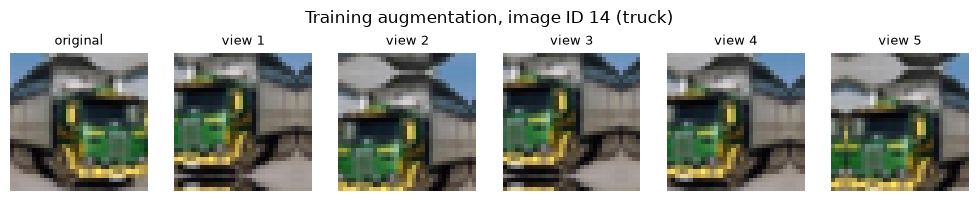

In [10]:
set_seed(SPLIT_SEED)
augment = training_augmentation()
raw, target, image_id = RawImages(database, val_ids)[0]
views = [raw] + [augment(raw) for _ in range(5)]
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, (ax, view) in enumerate(zip(axes, views)):
    ax.imshow(view.permute(1, 2, 0))
    ax.set_title("original" if i == 0 else f"view {i}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Training augmentation, image ID {image_id} ({CLASS_NAMES[target]})")
fig.tight_layout()
save(fig, "augmentation_views")
plt.show()

## How do we control the randomness?

The split uses seed 2223 and the IDs are saved, `set_seed(run.seed)` is called before building each model (weight init and dropout), the DataLoader shuffles with its own seeded generator, the augmentation uses the seeded torch RNG, and cuDNN is set to deterministic with benchmark turned off.

The cell below checks that this actually works. One thing to keep in mind is that results still won't be exactly identical on a different GPU or PyTorch version, so for anything important it's probably worth trying a couple of seeds.

In [11]:
checks = {}

# 1. saved split is the same as a fresh split with the same seed
fresh_train, fresh_val = make_split(labels, SPLIT_SEED)
checks["split reproducible from seed"] = np.array_equal(fresh_train, train_ids) and np.array_equal(fresh_val, val_ids)

# 2. same seed -> same batch order (and same augmented images), different seed -> different order
def first_batch_ids(seed, augmentation=False):
    set_seed(seed)
    run = SimpleNamespace(batch_size=64, seed=seed, augmentation=augmentation)
    raw, _, ids = next(iter(make_loaders(run, database, train_ids, val_ids)["train"]))
    return ids, raw

ids_a, raw_a = first_batch_ids(42, augmentation=True)
ids_b, raw_b = first_batch_ids(42, augmentation=True)
ids_c, _ = first_batch_ids(7)
checks["same seed, same batch order"] = torch.equal(ids_a, ids_b)
checks["same seed, same augmented pixels"] = torch.equal(raw_a, raw_b)
checks["different seed, different order"] = not torch.equal(ids_a, ids_c)

# 3. validation loader is always the same and not augmented
run = SimpleNamespace(batch_size=64, seed=42, augmentation=True)
loaders = make_loaders(run, database, train_ids, val_ids)
v1 = next(iter(loaders["val"]))
v2 = next(iter(loaders["val"]))
checks["validation loader fixed and unaugmented"] = torch.equal(v1[0], v2[0]) and torch.equal(v1[2], torch.as_tensor(val_ids[:64]))

# 4. test loader only has the official test images
test_loader = make_test_loader(test_database)
checks["test loader covers official test set only"] = len(test_loader.dataset) == 10_000

display(pd.DataFrame({"passed": checks}))
assert all(checks.values()), "A reproducibility check failed"

,passed
split reproducible from seed,True
"same seed, same batch order",True
"same seed, same augmented pixels",True
"different seed, different order",True
validation loader fixed and unaugmented,True
test loader covers official test set only,True


## Summary

We use a 45k/5k train/val split (stratified, seed 2223) and only touch the official 10k test set at the end. Image IDs are the index in the original dataset and are saved in `splits/cifar10_split.json`. Both models use 32x32 inputs with no resizing, normalised with the training mean and std inside `prepare_inputs`. Augmentation (crop + flip) is off by default and is there for Task 4.

For the other tasks, just start with:

```python
from cifar_data import load_cifar10, get_split, make_loaders, make_test_loader, prepare_inputs, set_seed
data = load_cifar10()
database, test_database = data["train"], data["test"]
split = get_split(database)
train_ids, val_ids, stats = split["train_ids"], split["val_ids"], split["stats"]
```

The Part A functions (`train_epoch`, `evaluate`, `predict`) use `database` and `stats`, so they should work as they are.